In [1]:
import sklearn
import torch
from sklearn.datasets import make_circles
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_predict
from torch import nn

In [2]:
n_samples = 1000
#2 klase y - je binarna
X,y = make_circles(n_samples,
                   noise=0.03,
                   random_state=42)

In [3]:
len(X), len(y)

(1000, 1000)

In [4]:
circles = pd.DataFrame({"X1:": X[:,0],
                        "X2:": X[:,1],
                        "label:": y})
circles.head()

,X1:,X2:,label:
0,0.754246,0.231481,1
1,-0.756159,0.153259,1
2,-0.815392,0.173282,1
3,-0.393731,0.692883,1
4,0.442208,-0.896723,0


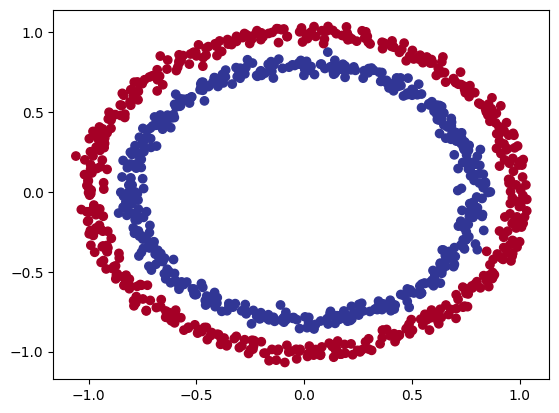

In [5]:
plt.scatter(x=X[:,0],
            y=X[:,1],
            c=y,
            cmap=plt.cm.RdYlBu)

In [6]:
X.shape, y.shape

((1000, 2), (1000,))

In [7]:
X_sample = X[0]
y_sample = y[0]
print(X_sample)
print(y_sample)

[0.75424625 0.23148074]
1


In [8]:
X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)
X[:5],y[:5]

(tensor([[ 0.7542,  0.2315],
         [-0.7562,  0.1533],
         [-0.8154,  0.1733],
         [-0.3937,  0.6929],
         [ 0.4422, -0.8967]]),
 tensor([1., 1., 1., 1., 0.]))

In [9]:
from sklearn.model_selection import train_test_split

In [10]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2, random_state=42)


In [11]:
class CircleModelV0(nn.Module):
    def __init__(self):
        super().__init__()
        #self.layer1 = nn.Linear(in_features=2,out_features=5)
        #self.layer2 = nn.Linear(in_features=5, out_features=1)
        self.two_linear_layers = nn.Sequential(
            nn.Linear(in_features=2,out_features=5),
            nn.Linear(in_features=5, out_features=1)
        )
    def forward(self,x:torch.Tensor) -> torch.Tensor:
        #return self.layer2(self.layer1(x))
        return self.two_linear_layers(x)

In [12]:
model = CircleModelV0().to("cuda")
model

CircleModelV0(
  (two_linear_layers): Sequential(
    (0): Linear(in_features=2, out_features=5, bias=True)
    (1): Linear(in_features=5, out_features=1, bias=True)
  )
)

In [13]:
with torch.inference_mode():
    untrained_preds = model(X_test.to("cuda"))
print(f"Length of predictions: {len(untrained_preds)}, shape: {untrained_preds.shape}\n")
print(f"Length of test samples: {len(X_test)}, shape: {X_test.shape}\n")
print(f"First 10 predictions: {untrained_preds[:10]}")
print(f"First 10 test values: {y_test[:10]}")

Length of predictions: 200, shape: torch.Size([200, 1])

Length of test samples: 200, shape: torch.Size([200, 2])

First 10 predictions: tensor([[0.4088],
        [0.4358],
        [0.4503],
        [0.3966],
        [0.6284],
        [0.6436],
        [0.5784],
        [0.6275],
        [0.4427],
        [0.4396]], device='cuda:0')
First 10 test values: tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.])


In [14]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model.parameters(),lr=0.01)

In [15]:
def accuracy(y_test,y_pred):
    correct = torch.eq(y_test,y_pred).sum().item()
    acc = (correct/len(y_test)) * 100
    return acc

In [16]:
model.eval()
with torch.inference_mode():
    y_logits = model(X_test.to("cuda"))
y_logits

tensor([[0.4088],
        [0.4358],
        [0.4503],
        [0.3966],
        [0.6284],
        [0.6436],
        [0.5784],
        [0.6275],
        [0.4427],
        [0.4396],
        [0.3878],
        [0.4257],
        [0.6084],
        [0.4872],
        [0.4177],
        [0.6194],
        [0.5065],
        [0.3665],
        [0.3950],
        [0.3681],
        [0.4332],
        [0.6626],
        [0.3924],
        [0.3540],
        [0.5337],
        [0.5989],
        [0.5649],
        [0.6686],
        [0.4068],
        [0.5136],
        [0.5535],
        [0.5221],
        [0.3907],
        [0.5919],
        [0.3785],
        [0.4643],
        [0.4111],
        [0.4754],
        [0.5706],
        [0.4995],
        [0.3890],
        [0.4229],
        [0.5104],
        [0.6425],
        [0.3855],
        [0.4727],
        [0.6507],
        [0.4267],
        [0.4589],
        [0.6372],
        [0.3949],
        [0.3846],
        [0.6623],
        [0.6297],
        [0.5862],
        [0

In [17]:
y_pred_probs = torch.sigmoid(y_logits)

y_preds = torch.round(y_pred_probs)
y_pred_labels = torch.round(torch.sigmoid(model(X_test.to("cuda"))))
print(torch.eq(y_preds.squeeze(),y_pred_labels.squeeze()))

y_preds.squeeze()


tensor([True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, Tr

tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1.], device='cuda:0')

In [18]:
epochs = 100

epochs_count = []
loss_values = []
test_loss_values = []

X_train, y_train = X_train.to("cuda"), y_train.to("cuda")
X_test, y_test = X_test.to("cuda"), y_test.to("cuda")

for epoch in range(epochs):
    model.train()

    y_logits = model(X_train).squeeze()
    y_pred = torch.round(torch.sigmoid(y_logits))

    loss = loss_fn(y_logits,y_train)
    acc = accuracy(y_train,y_pred)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    model.eval()

    with torch.inference_mode():
        test_logits = model(X_test).squeeze()
        test_pred = torch.round(torch.sigmoid(test_logits))
        test_loss = loss_fn(test_logits,y_test)
        test_acc = accuracy(y_test,test_pred)

    if epoch % 10 == 0:
        print(f"Epoch: {epoch}\n Loss: {loss}\n Accuracy: {acc}\n Test loss: {test_loss}\n Test accuracy: {test_acc}")

Epoch: 0
 Loss: 0.7273077368736267
 Accuracy: 50.0
 Test loss: 0.7255905270576477
 Test accuracy: 50.0
Epoch: 10
 Loss: 0.7243661880493164
 Accuracy: 50.0
 Test loss: 0.7228050827980042
 Test accuracy: 50.0
Epoch: 20
 Loss: 0.7216929197311401
 Accuracy: 50.0
 Test loss: 0.7202767133712769
 Test accuracy: 50.0
Epoch: 30
 Loss: 0.7192614674568176
 Accuracy: 50.0
 Test loss: 0.7179798483848572
 Test accuracy: 50.0
Epoch: 40
 Loss: 0.7170478701591492
 Accuracy: 50.0
 Test loss: 0.7158918380737305
 Test accuracy: 50.0
Epoch: 50
 Loss: 0.7150314450263977
 Accuracy: 50.0
 Test loss: 0.7139922976493835
 Test accuracy: 50.0
Epoch: 60
 Loss: 0.7131931185722351
 Accuracy: 50.0
 Test loss: 0.7122629880905151
 Test accuracy: 50.0
Epoch: 70
 Loss: 0.7115160226821899
 Accuracy: 50.0
 Test loss: 0.7106878757476807
 Test accuracy: 50.0
Epoch: 80
 Loss: 0.7099851965904236
 Accuracy: 50.0
 Test loss: 0.7092522382736206
 Test accuracy: 50.0
Epoch: 90
 Loss: 0.7085868120193481
 Accuracy: 50.0
 Test loss: 0

In [19]:
def plot_decision_boundary(model: torch.nn.Module, X: torch.Tensor, y: torch.Tensor):
    """Plots decision boundaries of model predicting on X in comparison to y.

    Source - https://madewithml.com/courses/foundations/neural-networks/ (with modifications)
    """
    # Put everything to CPU (works better with NumPy + Matplotlib)
    model.to("cpu")
    X, y = X.to("cpu"), y.to("cpu")

    # Setup prediction boundaries and grid
    x_min, x_max = X[:, 0].min() - 0.1, X[:, 0].max() + 0.1
    y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 101), np.linspace(y_min, y_max, 101))

    # Make features
    X_to_pred_on = torch.from_numpy(np.column_stack((xx.ravel(), yy.ravel()))).float()

    # Make predictions
    model.eval()
    with torch.inference_mode():
        y_logits = model(X_to_pred_on)

    # Test for multi-class or binary and adjust logits to prediction labels
    if len(torch.unique(y)) > 2:
        y_pred = torch.softmax(y_logits, dim=1).argmax(dim=1)  # mutli-class
    else:
        y_pred = torch.round(torch.sigmoid(y_logits))  # binary

    # Reshape preds and plot
    y_pred = y_pred.reshape(xx.shape).detach().numpy()
    plt.contourf(xx, yy, y_pred, cmap=plt.cm.RdYlBu, alpha=0.7)
    plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.RdYlBu)
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())

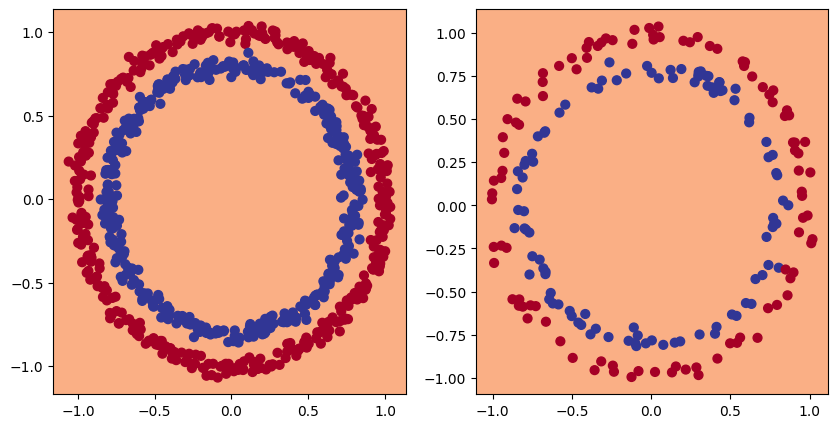

In [20]:
import numpy as np
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plot_decision_boundary(model,X_train,y_train)
plt.subplot(1,2,2)
plot_decision_boundary(model,X_test,y_test)

In [21]:
class CircleModelV1(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(in_features=2,out_features=10)
        self.layer2 = nn.Linear(in_features=10,out_features=10)
        self.layer3 = nn.Linear(in_features=10,out_features=1)
    def forward(self, x):
        return self.layer3(self.layer2(self.layer1(x)))


In [22]:
model1 = CircleModelV1().to("cuda")

In [23]:
model1.state_dict()

OrderedDict([('layer1.weight',
              tensor([[-4.9906e-01,  4.1762e-01],
                      [-6.4263e-01,  1.0629e-01],
                      [-6.4316e-01, -5.8085e-04],
                      [ 6.8226e-01, -2.3182e-01],
                      [-1.0680e-01, -3.3619e-01],
                      [ 5.4374e-01,  5.9412e-01],
                      [ 6.2138e-01,  1.0341e-01],
                      [ 3.6805e-01, -2.8763e-01],
                      [-5.3204e-01,  1.3620e-01],
                      [ 4.4317e-01,  9.9542e-02]], device='cuda:0')),
             ('layer1.bias',
              tensor([-0.4428,  0.4132, -0.2143, -0.4587,  0.1470,  0.5821, -0.5204,  0.5385,
                      -0.2033, -0.4419], device='cuda:0')),
             ('layer2.weight',
              tensor([[ 0.2912,  0.1974,  0.2246, -0.0359,  0.0868, -0.1592, -0.2974, -0.2560,
                       -0.1935, -0.1197],
                      [ 0.3073,  0.1754,  0.1805, -0.0750, -0.0935, -0.1175,  0.1770, -0.0456,
   

In [24]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(params=model1.parameters(),
                            lr=0.1)
torch.manual_seed(42)
torch.cuda.manual_seed(42)

In [25]:
epochs = 1000

X_train, y_train = X_train.to("cuda"), y_train.to("cuda")
X_test, y_test = X_test.to("cuda"), y_test.to("cuda")

for epoch in range(epochs):
    model1.train()
    y_logits = model1(X_train).squeeze()
    y_pred = torch.round(torch.sigmoid(y_logits))
    loss = loss_fn(y_logits, y_train)
    acc = accuracy(y_train,y_pred)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    model1.eval()
    with torch.inference_mode():
        test_logits = model1(X_test).squeeze()
        test_pred = torch.round(torch.sigmoid(test_logits))
        test_loss = loss_fn(test_logits, y_test)
        test_acc = accuracy(y_train, y_pred)

    if epoch % 100 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f} | Acc: {acc:.2f} | Test loss: {test_loss:.5f} | Test acc: {test_acc:.2f}")

Epoch: 0 | Loss: 0.69442 | Acc: 50.75 | Test loss: 0.69284 | Test acc: 50.75
Epoch: 100 | Loss: 0.69306 | Acc: 51.25 | Test loss: 0.69357 | Test acc: 51.25
Epoch: 200 | Loss: 0.69301 | Acc: 51.38 | Test loss: 0.69407 | Test acc: 51.38
Epoch: 300 | Loss: 0.69299 | Acc: 51.38 | Test loss: 0.69431 | Test acc: 51.38
Epoch: 400 | Loss: 0.69298 | Acc: 51.00 | Test loss: 0.69446 | Test acc: 51.00
Epoch: 500 | Loss: 0.69298 | Acc: 51.38 | Test loss: 0.69455 | Test acc: 51.38
Epoch: 600 | Loss: 0.69298 | Acc: 51.25 | Test loss: 0.69460 | Test acc: 51.25
Epoch: 700 | Loss: 0.69298 | Acc: 51.25 | Test loss: 0.69463 | Test acc: 51.25
Epoch: 800 | Loss: 0.69298 | Acc: 51.12 | Test loss: 0.69465 | Test acc: 51.12
Epoch: 900 | Loss: 0.69298 | Acc: 51.12 | Test loss: 0.69466 | Test acc: 51.12


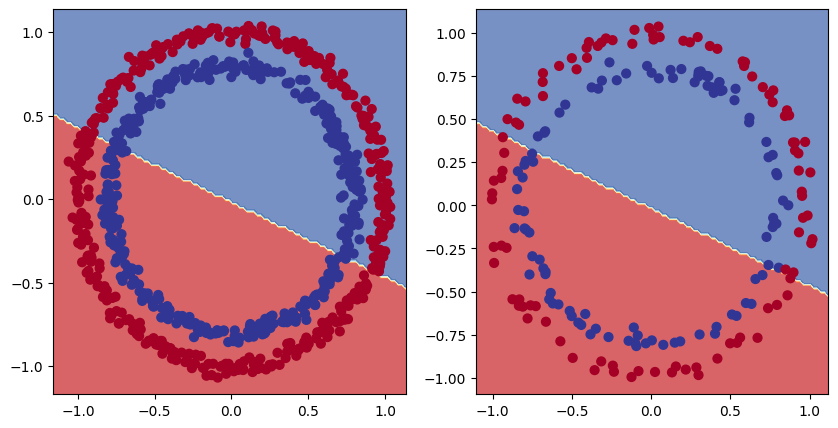

In [26]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plot_decision_boundary(model1,X_train,y_train)
plt.subplot(1,2,2)
plot_decision_boundary(model1,X_test,y_test)

TESTIRANJE NA MANJEM PROBLEMU

In [27]:
weight = 0.7
bias = 0.3

X_regression = torch.arange(0,1,0.01).unsqueeze(dim=1)
y_regression = X_regression*weight + bias

X_regression[:5],y_regression[:5]

(tensor([[0.0000],
         [0.0100],
         [0.0200],
         [0.0300],
         [0.0400]]),
 tensor([[0.3000],
         [0.3070],
         [0.3140],
         [0.3210],
         [0.3280]]))

In [28]:
train_split = int(0.8*len(X_regression))
X_train_reg,y_train_reg = X_regression[:train_split], y_regression[:train_split]
X_test_reg,y_test_reg = X_regression[train_split:], y_regression[train_split:]

len(X_train_reg),len(X_test_reg),len(y_train_reg),len(y_test_reg)

(80, 20, 80, 20)

Adjusting model1 to fit the straight line

In [29]:
model2 = nn.Sequential(
    nn.Linear(in_features=1,out_features=10),
    nn.Linear(in_features=10,out_features=10),
    nn.Linear(in_features=10,out_features=1)
).to("cuda")

model2

Sequential(
  (0): Linear(in_features=1, out_features=10, bias=True)
  (1): Linear(in_features=10, out_features=10, bias=True)
  (2): Linear(in_features=10, out_features=1, bias=True)
)

In [30]:
loss_fn = nn.L1Loss()
optimizer = torch.optim.SGD(params=model2.parameters(),
                            lr = 0.01)

In [31]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)
epochs = 1000

X_train_reg,y_train_reg = X_train_reg.to("cuda"), y_train_reg.to("cuda")
X_test_reg,y_test_reg = X_test_reg.to("cuda"), y_test_reg.to("cuda")

for epoch in range(epochs):
    model2.train()
    y_pred = model2(X_train_reg)
    loss = loss_fn(y_pred,y_train_reg)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    model2.eval()
    with torch.inference_mode():
        test_pred = model2(X_test_reg)
        test_loss = loss_fn(test_pred,y_test_reg)

    if epoch % 100 == 0:
        print(f"Epoch: {epoch} | Loss: {loss} | Test loss: {test_loss}")

Epoch: 0 | Loss: 0.7598585486412048 | Test loss: 0.9110288619995117
Epoch: 100 | Loss: 0.028579523786902428 | Test loss: 0.000812724232673645
Epoch: 200 | Loss: 0.02532540075480938 | Test loss: 0.002092051552608609
Epoch: 300 | Loss: 0.021374836564064026 | Test loss: 0.0030510008800774813
Epoch: 400 | Loss: 0.01964496821165085 | Test loss: 0.0034077675081789494
Epoch: 500 | Loss: 0.01940229907631874 | Test loss: 0.003872624132782221
Epoch: 600 | Loss: 0.019032571464776993 | Test loss: 0.003789240261539817
Epoch: 700 | Loss: 0.018783053383231163 | Test loss: 0.0038135708309710026
Epoch: 800 | Loss: 0.0183974951505661 | Test loss: 0.0032874345779418945
Epoch: 900 | Loss: 0.017980331555008888 | Test loss: 0.0036037624813616276


In [32]:
def plot_predictions(train_data=X_train,
                     train_labels=y_train,
                     test_data=X_test,
                     test_labels=y_test,
                     predictions=None):
    plt.figure(figsize=(7,5))
    plt.scatter(train_data,train_labels,c="b",s=4,label="Training data")
    plt.scatter(test_data,test_labels,c="g",s=4,label="Testing data")
    if predictions is not None:
        plt.scatter(test_data, predictions,c="r",s=4,label="Predicted data")

    plt.legend()

Non linear data

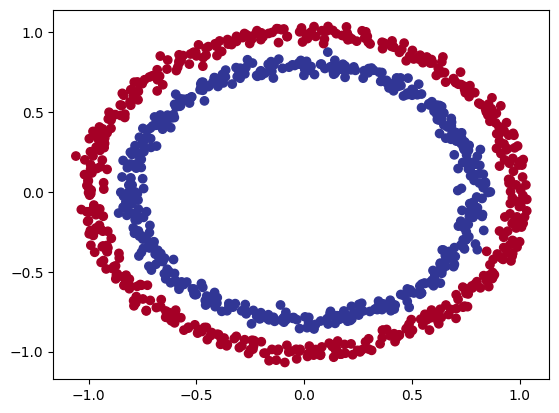

In [34]:
n_samples = 1000

X, y = make_circles(n_samples, noise=0.03,random_state=42)

plt.scatter(X[:,0],X[:,1],c=y,cmap=plt.cm.RdYlBu)

In [35]:
#Convert data to tensors and train test split
from sklearn.model_selection import train_test_split

X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2, random_state=42)
X_train[:5],y_train[:5]

(tensor([[ 0.6579, -0.4651],
         [ 0.6319, -0.7347],
         [-1.0086, -0.1240],
         [-0.9666, -0.2256],
         [-0.1666,  0.7994]]),
 tensor([1., 0., 0., 0., 1.]))

In [36]:
class CircleModelV2(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(in_features=2,out_features=10)
        self.layer2 = nn.Linear(in_features=10,out_features=10)
        self.layer3 = nn.Linear(in_features=10,out_features=1)
        self.relu  = nn.ReLU() #non linear activation function

    def forward(self,x):
        return self.layer3(self.relu(self.layer2(self.relu(self.layer1(x)))))

model3 = CircleModelV2().to("cuda")
model3

CircleModelV2(
  (layer1): Linear(in_features=2, out_features=10, bias=True)
  (layer2): Linear(in_features=10, out_features=10, bias=True)
  (layer3): Linear(in_features=10, out_features=1, bias=True)
  (relu): ReLU()
)

In [37]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model3.parameters(), lr = 0.1)



In [41]:
#Training
torch.manual_seed(42)
torch.cuda.manual_seed(42)

X_train,y_train = X_train.to("cuda"), y_train.to("cuda")
X_test,y_test = X_test.to("cuda"), y_test.to("cuda")

epochs = 1000

for epoch in range(epochs):
    model3.train()
    y_logits = model3(X_train).squeeze()
    y_pred = torch.round(torch.sigmoid(y_logits))

    loss = loss_fn(y_logits, y_train)
    acc = accuracy(y_train,y_pred)
    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    model3.eval()
    with torch.inference_mode():
        test_logits = model3(X_test).squeeze()
        test_pred = torch.round(torch.sigmoid(test_logits))

        test_loss = loss_fn(test_logits, y_test)
        test_acc = accuracy(y_test, test_pred)

    if epoch % 100 == 0:
        print(f" Epoch: {epoch} | Loss: {loss} | Acc: {acc} | Test loss: {test_loss} | Test acc: {test_acc}")

 Epoch: 0 | Loss: 0.6928943991661072 | Acc: 50.0 | Test loss: 0.6931213140487671 | Test acc: 50.0
 Epoch: 100 | Loss: 0.6911401152610779 | Acc: 52.87500000000001 | Test loss: 0.6910093426704407 | Test acc: 52.5
 Epoch: 200 | Loss: 0.6897588968276978 | Acc: 53.25 | Test loss: 0.6893777251243591 | Test acc: 55.50000000000001
 Epoch: 300 | Loss: 0.6879280805587769 | Acc: 53.0 | Test loss: 0.6872065663337708 | Test acc: 56.00000000000001
 Epoch: 400 | Loss: 0.6851330399513245 | Acc: 52.75 | Test loss: 0.6840771436691284 | Test acc: 56.49999999999999
 Epoch: 500 | Loss: 0.6809730529785156 | Acc: 52.75 | Test loss: 0.67935711145401 | Test acc: 56.49999999999999
 Epoch: 600 | Loss: 0.6750780940055847 | Acc: 54.50000000000001 | Test loss: 0.6727732419967651 | Test acc: 56.49999999999999
 Epoch: 700 | Loss: 0.6664816737174988 | Acc: 58.375 | Test loss: 0.6630982160568237 | Test acc: 59.0
 Epoch: 800 | Loss: 0.6514018177986145 | Acc: 64.0 | Test loss: 0.6473753452301025 | Test acc: 67.5
 Epoch: 

In [42]:
model3.eval()
with torch.inference_mode():
    y_preds = torch.round(torch.sigmoid(model3(X_test))).squeeze()
y_preds[:10],y_test[:10]

(tensor([1., 0., 1., 0., 0., 1., 0., 0., 1., 0.], device='cuda:0'),
 tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.], device='cuda:0'))

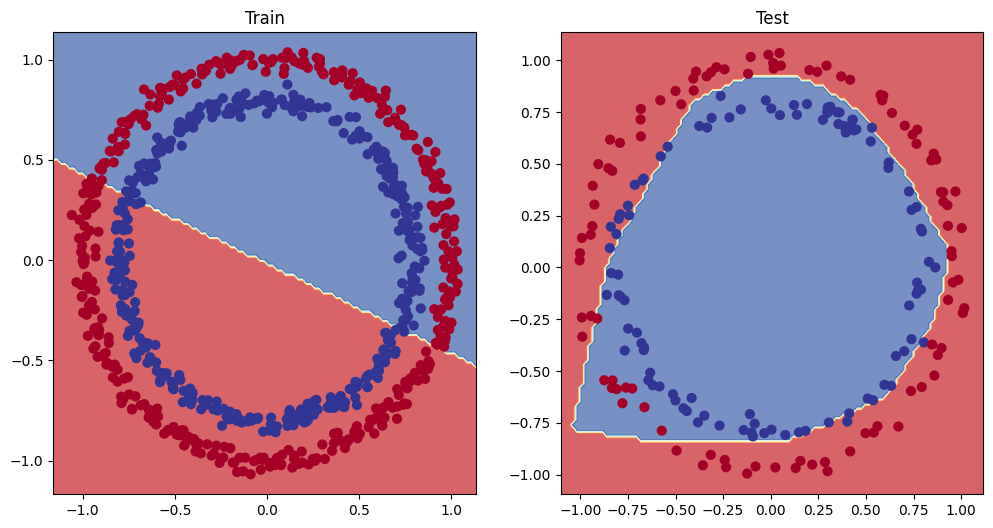

In [44]:
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title("Train")
plot_decision_boundary(model1,X_train,y_train)
plt.subplot(1,2,2)
plt.title("Test")
plot_decision_boundary(model3,X_test,y_test)